In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import dask.dataframe as dd
from xgboost import XGBClassifier
from scipy.stats.mstats import winsorize
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import precision_score, recall_score, roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import shutil
import optuna
import lightgbm as lgb
import shap
from scipy.stats import skew


## Big Data Handling

In [2]:
# 1) convert to parquet: it is better to take all three csv files (even KYC) in parquet using dask

df1 = dd.read_parquet([
    "/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/kyc.parquet"
])

df2 = dd.read_parquet([
    "/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/transactions/trx_2024-03.parquet",
"/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/transactions/trx_2024-01.parquet",
"/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/transactions/trx_2024-02.parquet"
])

df3 = dd.read_parquet([
    "/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/dayend_balance/balance_2024-01.parquet",
"/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/dayend_balance/balance_2024-03.parquet",
"/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/dayend_balance/balance_2024-02.parquet"
])


train = dd.read_csv("/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/train_labels.csv")
test = dd.read_csv("/kaggle/input/competitions/bkash-presents-nsucec-datathon/public/test.csv")


# 2) load them in dask dataframes lazily: (don't put .compute() unless showing the result)

# justification of choosing dask:
# Dask is Python-native, zero JVM overhead, and works in notebooks — perfect for a datathon environment.


## Column Pruning and Partitioning

In [3]:
# 3) use column pruning(only load cols you need) and partitioning

outgoing = df2[["SRC_ACCOUNT", "TRX_DATETIME", "TRX_TYPE", "DST_ACCOUNT", "TRX_AMT"]]
outgoing = outgoing.rename(columns = {"SRC_ACCOUNT" : "ACCOUNT_ID"})
outgoing["DIRECTION"] = "out"
outgoing["SRC_ACCOUNT"] = outgoing["ACCOUNT_ID"]
incoming = df2[["DST_ACCOUNT", "TRX_DATETIME", "TRX_TYPE", "SRC_ACCOUNT", "TRX_AMT"]]
incoming = incoming.rename(columns = {"DST_ACCOUNT" : "ACCOUNT_ID"})
incoming["DIRECTION"] = "in"
incoming["DST_ACCOUNT"] = incoming["ACCOUNT_ID"]
df = dd.concat([outgoing, incoming], axis = 0)

## Data Analysis

In [4]:
# 5) find out the information in all 3 files 
## (shape, columns, contents, missing values, .describe() etc)

df1.isna().mean().compute()
df2.isna().mean().compute()
df3.isna().mean().compute()

ACCOUNT_ID           0.0
DATE                 0.0
AVAILABLE_BALANCE    0.0
dtype: float64

## Data Cleaning

In [5]:
# 6) clean the data:
# (missing values, convert dtype of columns if required etc)
# churn means inactive for 30 days. 'Churn' column might be in 0/1 binary form.

df1 = df1.fillna({
    "GENDER": "Unknown"
})

df1.isna().mean().compute()

ACCOUNT_ID           0.0
ACCOUNT_TYPE         0.0
ACCOUNT_OPEN_DATE    0.0
GENDER               0.0
REGION               0.0
dtype: float64

In [7]:
df1["ACCOUNT_OPEN_DATE"] = dd.to_datetime(df1["ACCOUNT_OPEN_DATE"])
df2["TRX_DATETIME"] = dd.to_datetime(df2["TRX_DATETIME"])

## Sampling

In [ ]:
# 7) choose sample: we'll use it for the rest part (stratified sampling on entities might be an option)
# 8) save the sample permanently, as we are going to work on this
# Document the sampling strategy for safe interactive EDA -4 points)

In [7]:
#keep only account_ids of train file

sample_df = df2.merge(
    train[["ACCOUNT_ID"]],
    left_on="SRC_ACCOUNT",
    right_on="ACCOUNT_ID",
    how="inner"
)

sample_df3 = df3.merge(
    train[["ACCOUNT_ID"]],
    left_on="ACCOUNT_ID",
    right_on="ACCOUNT_ID",
    how="inner"
)

sample2 = sample_df["TRX_AMT"].sample(frac=0.00005).compute()
sample3 = sample_df3["AVAILABLE_BALANCE"].sample(frac=0.00005).compute()

## Exploratory Data Analysis

In [ ]:
# 9) exploratory data analysis: (can use plots, maps etc for better visualization)

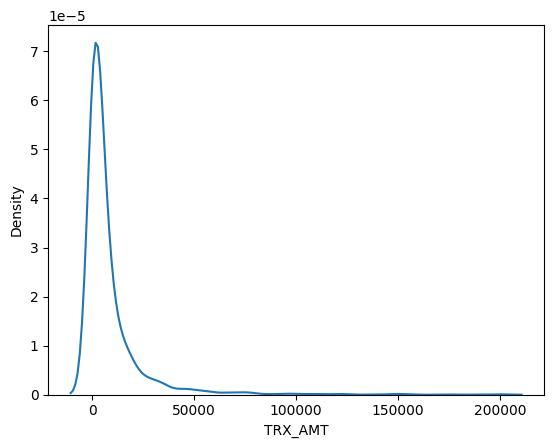

In [8]:
#density curve of trx_amt

sns.kdeplot(sample2)
plt.show()

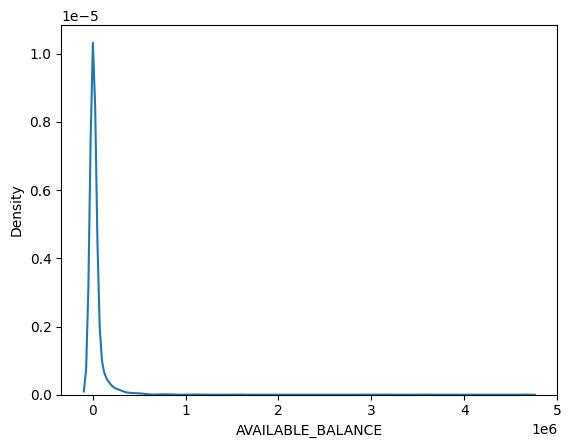

In [9]:
#density curve of available_balance

sns.kdeplot(sample3)
plt.show()

## Feature Extraction

In [ ]:
#--Clearly list all features (>=10, better 15) including recency, frequency, monetary, balance, type-ratio, tenure, service_diversity etc.

#--Implement all features properly. Make sure that all features are numeric, otherwise further processing
#  would be tougher

#--Mention proper reasoning behind considering every feature

In [8]:
# recency: last_trx_date-today. recency high-> churn probability high.

max_date = df2["TRX_DATETIME"].max().compute()

df_ro = (
    df2.groupby("SRC_ACCOUNT")["TRX_DATETIME"]
       .max()
       .reset_index()
)

df_ro["RECENCY"] = (max_date - df_ro["TRX_DATETIME"]).dt.days
df_ro = df_ro[["SRC_ACCOUNT", "RECENCY"]]

df_ri = (
    df2.groupby("DST_ACCOUNT")["TRX_DATETIME"]
       .max()
       .reset_index()
)

df_ri["RECENCY"] = (max_date - df_ri["TRX_DATETIME"]).dt.days
df_ri = df_ri[["DST_ACCOUNT", "RECENCY"]]

df_ro = df_ro.rename(columns={"SRC_ACCOUNT": "ACCOUNT_ID"})
df_ri = df_ri.rename(columns={"DST_ACCOUNT": "ACCOUNT_ID"})

df_recency = dd.concat([df_ro, df_ri])
df_recency = df_recency.groupby("ACCOUNT_ID")["RECENCY"].max().reset_index()

final = df1[["ACCOUNT_ID"]]
final = final.merge(df_recency, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["RECENCY"] = final["RECENCY"].fillna(final["RECENCY"].mean().compute())

In [9]:
# frequency over the period

# Outgoing frequency
df_fo = (
    df2[df2["SRC_ACCOUNT"].str.startswith("CUST")].groupby("SRC_ACCOUNT")
       .size()
       .reset_index()
       .rename(columns={
           "SRC_ACCOUNT": "ACCOUNT_ID",
           0: "FREQ_OUT"
       })
)

# Incoming frequency
df_fi = (
    df2[df2["DST_ACCOUNT"].str.startswith("CUST")].groupby("DST_ACCOUNT")
       .size()
       .reset_index()
       .rename(columns={
           "DST_ACCOUNT": "ACCOUNT_ID",
           0: "FREQ_IN"
       })
)

# Merge
df_freq = df_fo.merge(df_fi, on="ACCOUNT_ID", how="outer")

# Total frequency
df_freq["FREQUENCY"] = (
    df_freq["FREQ_OUT"].fillna(0)
    + df_freq["FREQ_IN"].fillna(0)
)

df_freq = df_freq[["ACCOUNT_ID", "FREQUENCY"]]
final = final.merge(df_freq, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["FREQUENCY"] = final["FREQUENCY"].fillna(final["FREQUENCY"].mean().compute())

In [10]:
#frequency_30 days

start_date = max_date - pd.Timedelta(days = 30)
trx30 = df2[df2["TRX_DATETIME"] >= start_date]
df_fo = (
    trx30[trx30["SRC_ACCOUNT"].str.startswith("CUST")].groupby("SRC_ACCOUNT")["TRX_AMT"]
    .size()
    .reset_index()
    .rename(columns={
        "SRC_ACCOUNT" : "ACCOUNT_ID", 
        "TRX_AMT": "FREQ_OUT", 0: "FREQ_OUT"
    })
)

df_fi = (
    trx30[trx30["SRC_ACCOUNT"].str.startswith("CUST")].groupby("DST_ACCOUNT")["TRX_AMT"]
       .size()
       .reset_index()
       .rename(columns={
           "DST_ACCOUNT": "ACCOUNT_ID",
           0: "FREQ_IN", "TRX_AMT": "FREQ_IN"
       })
)


df_freq = df_fo.merge(df_fi, on="ACCOUNT_ID", how="outer")

# Total frequency
df_freq["FREQUENCY_30D"] = (
    df_freq["FREQ_OUT"].fillna(0)
    + df_freq["FREQ_IN"].fillna(0)
)

df_freq = df_freq[["ACCOUNT_ID", "FREQUENCY_30D"]]
final = final.merge(df_freq, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["FREQUENCY_30D"] = final["FREQUENCY_30D"].fillna(final["FREQUENCY_30D"].mean().compute())

In [10]:
#frequency_prev_30 days

end_date = start_date
start_date = max_date - pd.Timedelta(days = 60)

trx30prev = df2[df2["TRX_DATETIME"].between(start_date, end_date)]
df_fo = (
    trx30prev[trx30prev["SRC_ACCOUNT"].str.startswith("CUST")].groupby("SRC_ACCOUNT")["TRX_AMT"]
    .size()
    .reset_index()
    .rename(columns={
        "SRC_ACCOUNT" : "ACCOUNT_ID", 
        "TRX_AMT": "FREQ_OUT", 0: "FREQ_OUT"
    })
)

df_fi = (
    trx30prev[trx30prev["SRC_ACCOUNT"].str.startswith("CUST")].groupby("DST_ACCOUNT")["TRX_AMT"]
       .size()
       .reset_index()
       .rename(columns={
           "DST_ACCOUNT": "ACCOUNT_ID",
           0: "FREQ_IN", "TRX_AMT": "FREQ_IN"
       })
)


df_freq = df_fo.merge(df_fi, on="ACCOUNT_ID", how="outer")

# Total frequency
df_freq["FREQUENCY_30Dprev"] = (
    df_freq["FREQ_OUT"].fillna(0)
    + df_freq["FREQ_IN"].fillna(0)
)

df_freq = df_freq[["ACCOUNT_ID", "FREQUENCY_30Dprev"]]
final = final.merge(df_freq, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["FREQUENCY_30Dprev"] = final["FREQUENCY_30Dprev"].fillna(final["FREQUENCY_30Dprev"].mean().compute())

In [11]:
#30D/30Dprev ratio

final["FREQUENCY_30D/FREQUENCY_30Dprev"] = (
    final["FREQUENCY_30D"] / final["FREQUENCY_30Dprev"]
).where(final["FREQUENCY_30Dprev"] != 0, 0)

In [12]:
#frequency_90 days

start_date = max_date - pd.Timedelta(days = 90)
trx90 = df2[df2["TRX_DATETIME"] >= start_date]
df_fo = (
    trx90[trx90["SRC_ACCOUNT"].str.startswith("CUST")].groupby("SRC_ACCOUNT")["TRX_AMT"]
    .size()
    .reset_index()
    .rename(columns={
        "SRC_ACCOUNT" : "ACCOUNT_ID", 
        "TRX_AMT": "FREQ_OUT", 0: "FREQ_OUT"
    })
)

df_fi = (
    trx90[trx90["SRC_ACCOUNT"].str.startswith("CUST")].groupby("DST_ACCOUNT")["TRX_AMT"]
       .size()
       .reset_index()
       .rename(columns={
           "DST_ACCOUNT": "ACCOUNT_ID",
           0: "FREQ_IN", "TRX_AMT": "FREQ_IN"
       })
)


df_freq = df_fo.merge(df_fi, on="ACCOUNT_ID", how="outer")

# Total frequency
df_freq["FREQUENCY_90D"] = (
    df_freq["FREQ_OUT"].fillna(0)
    + df_freq["FREQ_IN"].fillna(0)
)

df_freq = df_freq[["ACCOUNT_ID", "FREQUENCY_90D"]]
final = final.merge(df_freq, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["FREQUENCY_90D"] = final["FREQUENCY_90D"].fillna(final["FREQUENCY_90D"].mean().compute())

In [13]:
# ACTIVE_DAYS_30D

start_date = max_date - pd.Timedelta(days=30)

trx30 = df2[df2["TRX_DATETIME"] >= start_date].copy()

trx30["TRX_DATE"] = trx30["TRX_DATETIME"].dt.date

out_df = (
    trx30[trx30["SRC_ACCOUNT"].str.startswith("CUST")]
    [["SRC_ACCOUNT", "TRX_DATE"]]
    .rename(columns={"SRC_ACCOUNT": "ACCOUNT_ID"})
)

in_df = (
    trx30[trx30["DST_ACCOUNT"].str.startswith("CUST")]
    [["DST_ACCOUNT", "TRX_DATE"]]
    .rename(columns={"DST_ACCOUNT": "ACCOUNT_ID"})
)
activity = dd.concat([out_df, in_df])

activity = activity.drop_duplicates(
    subset=["ACCOUNT_ID", "TRX_DATE"]
)

df_active = (
    activity.groupby("ACCOUNT_ID")
    .size()
    .reset_index()
    .rename(columns={0: "ACTIVE_DAYS_30D"})
)

final = final.merge(df_active, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["ACTIVE_DAYS_30D"] = (final["ACTIVE_DAYS_30D"].fillna(final["ACTIVE_DAYS_30D"].mean().compute()))

In [11]:
# iii) monetary: total_trxAMT/30days

mon_out = trx30[trx30["SRC_ACCOUNT"].str.startswith("CUST")].groupby("SRC_ACCOUNT")["TRX_AMT"].sum().reset_index().rename(columns={"SRC_ACCOUNT" : "ACCOUNT_ID", "TRX_AMT": "MON_OUT", 0: "MON_OUT"})
mon_in = trx30[trx30["DST_ACCOUNT"].str.startswith("CUST")].groupby("DST_ACCOUNT")["TRX_AMT"].sum().reset_index().rename(columns={"DST_ACCOUNT" : "ACCOUNT_ID", "TRX_AMT": "MON_IN", 0: "MON_IN"})
df_mon = mon_out.merge(mon_in, on="ACCOUNT_ID", how="outer")

df_mon["MONETARY"] = (
    df_mon["MON_OUT"].fillna(0)
    + df_mon["MON_IN"].fillna(0)
)

df_mon = df_mon[["ACCOUNT_ID", "MONETARY"]]
final = final.merge(df_mon, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["MONETARY"] = final["MONETARY"].fillna(final["MONETARY"].mean().compute())

In [12]:
# v) type-ratio: bill pay / total txns

b =df2[(df2["SRC_ACCOUNT"].str.startswith("CUST")) & (df2["TRX_TYPE"] == "BillPay")].groupby("SRC_ACCOUNT").size().reset_index().rename(columns={"SRC_ACCOUNT" : "ACCOUNT_ID", 0: "BILLPAY"})
t_out = df2[df2["SRC_ACCOUNT"].str.startswith("CUST")].groupby("SRC_ACCOUNT").size().reset_index().rename(columns={"SRC_ACCOUNT" : "ACCOUNT_ID", 0: "OUT"})
t_in  = df2[df2["DST_ACCOUNT"].str.startswith("CUST")].groupby("DST_ACCOUNT").size().reset_index().rename(columns={"DST_ACCOUNT" : "ACCOUNT_ID", 0: "IN"})
bill = t_out.merge(b, on="ACCOUNT_ID", how="outer")
bill = bill.merge(t_in, on="ACCOUNT_ID", how="outer")

bill["BPR"] = bill["BILLPAY"].fillna(0) / (bill["OUT"].fillna(bill["OUT"].mean().compute()) + bill["IN"].fillna(bill["IN"].mean().compute()))
bill = bill[["ACCOUNT_ID", "BPR"]]
final = final.merge(bill, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["BPR"] = final["BPR"].fillna(final["BPR"].mean().compute())

In [13]:
# vi) tenure: account age

df1["TENURE"] = (max_date - df1["ACCOUNT_OPEN_DATE"]).dt.days
df_tenure = df1[df1["ACCOUNT_ID"].str.startswith("CUST")][["ACCOUNT_ID", "TENURE"]]
final = final.merge(df_tenure, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["TENURE"] = final["TENURE"].fillna(final["TENURE"].mean().compute())

In [14]:
# vii) service_diversity: how many different categories of transactions (since the creation of the account)

service_diversity_out= (
    df2[df2["SRC_ACCOUNT"].str.startswith("CUST")].groupby("SRC_ACCOUNT")["TRX_TYPE"]
    .nunique()
    .reset_index()
)

service_diversity_in = (
     df2[df2["DST_ACCOUNT"].str.startswith("CUST")].groupby("DST_ACCOUNT")["TRX_TYPE"]
    .nunique()
    .reset_index()
)

service_diversity = service_diversity_out.merge(
    service_diversity_in,
    left_on="SRC_ACCOUNT",
    right_on="DST_ACCOUNT",
    how="outer"
)

service_diversity["SERVICE_DIVERSITY"] = service_diversity["TRX_TYPE_x"].fillna(0) + service_diversity["TRX_TYPE_y"].fillna(0)

service_diversity = service_diversity.rename(columns = {"SRC_ACCOUNT" : "ACCOUNT_ID"})
service_diversity = service_diversity.drop(["DST_ACCOUNT", "TRX_TYPE_x", "TRX_TYPE_y"], axis = 1)

final = final.merge(service_diversity, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["SERVICE_DIVERSITY"] = final["SERVICE_DIVERSITY"].fillna(final["SERVICE_DIVERSITY"].mean().compute())

In [15]:
# viii) Balance_Volatility: Standard deviation of daily balances. High volatility may indicate unstable engagement.

balance_vol = df3[df3["ACCOUNT_ID"].str.startswith("CUST")].groupby("ACCOUNT_ID")["AVAILABLE_BALANCE"].std().reset_index().rename(columns = {"AVAILABLE_BALANCE" : "BALANCE_VOLATILITY"})

final = final.merge(balance_vol, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["BALANCE_VOLATILITY"] = final["BALANCE_VOLATILITY"].fillna(final["BALANCE_VOLATILITY"].mean().compute())

In [16]:
# viii) Trx_Amt_Volatility: Standard deviation of transaction amounts. High volatility may indicate unstable engagement.


out = df2[df2["SRC_ACCOUNT"].str.startswith("CUST")]
out= out[['SRC_ACCOUNT', 'TRX_AMT']]
out= out.rename(columns = {"SRC_ACCOUNT" : "ACCOUNT_ID"})

inn = df2[df2["DST_ACCOUNT"].str.startswith("CUST")]
inn= inn[['DST_ACCOUNT', 'TRX_AMT']]
inn= inn.rename(columns = {"DST_ACCOUNT" : "ACCOUNT_ID"})

all_trx = dd.concat([out, inn]).reset_index(drop=True)

new_df= all_trx.groupby('ACCOUNT_ID')["TRX_AMT"].std().reset_index().rename(columns = {"TRX_AMT" : "TRX_AMT_VOLATILITY"})

final = final.merge(new_df, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["TRX_AMT_VOLATILITY"] = final["TRX_AMT_VOLATILITY"].fillna(final["TRX_AMT_VOLATILITY"].mean().compute())

In [17]:
# ix) Trend slope: slope of transaction amount over time. Declining slope = disengagement.

out = df2[df2["SRC_ACCOUNT"].str.startswith("CUST")]
out = out[["SRC_ACCOUNT", "TRX_DATETIME", "TRX_AMT"]]
out = out.rename(columns={"SRC_ACCOUNT": "ACCOUNT_ID"})

inn = df2[df2["DST_ACCOUNT"].str.startswith("CUST")]
inn = inn[["DST_ACCOUNT", "TRX_DATETIME", "TRX_AMT"]]
inn = inn.rename(columns={"DST_ACCOUNT": "ACCOUNT_ID"})

df_trend = dd.concat([out, inn]).reset_index(drop=True)

first_trx = (
    df_trend.groupby("ACCOUNT_ID")["TRX_DATETIME"]
    .min()
    .reset_index()
    .rename(columns={"TRX_DATETIME": "FIRST_TRX"})
)

df_trend = df_trend.merge(first_trx, on="ACCOUNT_ID", how="inner")

df_trend["days_from_first_trx"] = (
    (df_trend["TRX_DATETIME"] - df_trend["FIRST_TRX"]).dt.days
)

df_trend["x"] = df_trend["days_from_first_trx"]
df_trend["y"] = df_trend["TRX_AMT"]
df_trend["xy"] = df_trend["x"] * df_trend["y"]
df_trend["x2"] = df_trend["x"] ** 2

agg = (
    df_trend.groupby("ACCOUNT_ID")
    .agg({"x": "mean", "y": "mean", "xy": "mean", "x2": "mean"})
    .reset_index()
)

agg["TREND_SLOPE"] = (agg["xy"] - agg["x"] * agg["y"]) / (
    agg["x2"] - agg["x"] ** 2
)

trend = agg[["ACCOUNT_ID", "TREND_SLOPE"]]

final = final.merge(trend, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["TREND_SLOPE"] = final["TREND_SLOPE"].fillna(final["TREND_SLOPE"].mean().compute())

In [24]:
# x) Dormancy streak: Longest consecutive inactive days.

# Calculated on Last 90 days

start_date = max_date - pd.Timedelta(days=90)

trx90 = df2[df2["TRX_DATETIME"] >= start_date].copy()

trx90["TRX_DATE"] = trx90["TRX_DATETIME"].dt.floor("D")

# Outgoing activity
out_df = (
    trx90[trx90["SRC_ACCOUNT"].str.startswith("CUST")]
    [["SRC_ACCOUNT", "TRX_DATE"]]
    .rename(columns={"SRC_ACCOUNT": "ACCOUNT_ID"})
)

# Incoming activity
in_df = (
    trx90[trx90["DST_ACCOUNT"].str.startswith("CUST")]
    [["DST_ACCOUNT", "TRX_DATE"]]
    .rename(columns={"DST_ACCOUNT": "ACCOUNT_ID"})
)

activity = dd.concat([out_df, in_df])

activity = activity.drop_duplicates(
    subset=["ACCOUNT_ID", "TRX_DATE"]
)

activity_pd = activity.compute()
activity_pd = activity_pd.sort_values(
    ["ACCOUNT_ID", "TRX_DATE"]
)

activity_pd["GAP"] = (
    activity_pd.groupby("ACCOUNT_ID")["TRX_DATE"]
    .diff()
    .dt.days
    .fillna(0)
)

longest_gap = (
    activity_pd.groupby("ACCOUNT_ID")["GAP"]
    .max()
    .reset_index()
    .rename(columns={"GAP": "LONGEST_INACTIVE_DAYS"})
)
final = final.merge(
    longest_gap,
    on="ACCOUNT_ID",
    how="outer"
)

final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["LONGEST_INACTIVE_DAYS"] = (
    final["LONGEST_INACTIVE_DAYS"]
    .fillna(
        final["LONGEST_INACTIVE_DAYS"].mean()
    )
)

In [18]:
# xi) Incoming vs Outgoing ratio: Compare credits vs debits. Customers with mostly outgoing flows may churn faster.

out = (
    df2[(df2["TRX_TYPE"].isin(["CashIn", "MerchantPay", "BillPay"])) & (df2["SRC_ACCOUNT"].str.startswith("CUST"))]
    .groupby("SRC_ACCOUNT")["TRX_AMT"]
    .sum().reset_index().rename(columns = {"SRC_ACCOUNT" : "ACCOUNT_ID"})
)
inn = (
    df2[(df2["TRX_TYPE"].isin(["CashIn", "MerchantPay", "BillPay"])) & (df2["DST_ACCOUNT"].str.startswith("CUST"))]
    .groupby("DST_ACCOUNT")["TRX_AMT"]
    .sum().reset_index().rename(columns = {"DST_ACCOUNT" : "ACCOUNT_ID"})
)
all_trx = out.merge(inn, on = "ACCOUNT_ID", how = "inner")
all_trx.columns = ["ACCOUNT_ID", "OUT", "IN"]
all_trx["OUT/IN"] = all_trx["OUT"] / all_trx["IN"]
all_trx = all_trx.drop(columns=["OUT", "IN"])

final = final.merge(all_trx, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["OUT/IN"] = final["OUT/IN"].fillna(final["OUT/IN"].mean().compute())

In [19]:
 # xii) Peer-to-Peer diversity: Count of unique counterparties (DST_ACCOUNT). More counterparties = stronger network stickiness.

peer_diversity_out= (
    df2[df2["SRC_ACCOUNT"].str.startswith("CUST")].groupby("SRC_ACCOUNT")["DST_ACCOUNT"]
    .nunique()
    .reset_index().rename(columns = {"SRC_ACCOUNT" : "ACCOUNT_ID"})
)
peer_diversity_in = (
     df2[df2["DST_ACCOUNT"].str.startswith("CUST")].groupby("DST_ACCOUNT")["SRC_ACCOUNT"]
    .nunique()
    .reset_index().rename(columns = {"DST_ACCOUNT" : "ACCOUNT_ID"})
)

peer_diversity = peer_diversity_out.merge(
    peer_diversity_in,
    on = "ACCOUNT_ID",
    how="inner"
)
peer_diversity["PEER_DIVERSITY"] = peer_diversity["SRC_ACCOUNT"] + peer_diversity["DST_ACCOUNT"]
peer_diversity = peer_diversity[["ACCOUNT_ID", "PEER_DIVERSITY"]]

final = final.merge(peer_diversity, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["PEER_DIVERSITY"] = final["PEER_DIVERSITY"].fillna(final["PEER_DIVERSITY"].mean().compute())

In [20]:
# xiii) Balance floor days: Number of days when balance ≤ threshold (threshold may be the minimum balance?!). Persistent low balance signals disengagement.

threshold = 100

floor_days = (
    df3[df3["AVAILABLE_BALANCE"] <= threshold]
    .groupby("ACCOUNT_ID")
    .size()
    .reset_index().rename(columns = {0 : "BALANCE_FLOOR_DAYS"})
)

final = final.merge(floor_days, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["BALANCE_FLOOR_DAYS"] = final["BALANCE_FLOOR_DAYS"].fillna(final["BALANCE_FLOOR_DAYS"].mean().compute())

In [30]:
# xv) Transaction velocity: Average time gap between transactions. Slowing velocity indicates fading activity.


activity = (
    df2[df2["SRC_ACCOUNT"].str.startswith("CUST")]
    [["SRC_ACCOUNT", "TRX_DATETIME"]]
    .rename(columns={"SRC_ACCOUNT": "ACCOUNT_ID"})
)

activity = activity.compute()

activity = activity.sort_values(
    ["ACCOUNT_ID", "TRX_DATETIME"]
)

activity["GAP_DAYS"] = (
    activity.groupby("ACCOUNT_ID")["TRX_DATETIME"]
    .diff()
    .dt.total_seconds()
    / 86400
)

avg_gap = (
    activity.groupby("ACCOUNT_ID")["GAP_DAYS"]
    .mean()
    .reset_index()
    .rename(columns={"GAP_DAYS": "AVG_TRX_GAP_DAYS"})
)

final = final.merge(avg_gap, on = "ACCOUNT_ID", how = "outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["AVG_TRX_GAP_DAYS"] = final["AVG_TRX_GAP_DAYS"].fillna(final["AVG_TRX_GAP_DAYS"].mean().compute)

In [21]:
# xix) transcation count 7D/30D:

end_date = max_date
start_date = end_date - pd.Timedelta(days=30)

df_30 = df2[df2["TRX_DATETIME"].between(start_date, end_date)]

out_cnt = (
    df_30.groupby("SRC_ACCOUNT")
         .size()
         .reset_index()
         .rename(columns={
             "SRC_ACCOUNT": "ACCOUNT_ID",
             0: "TXN_COUNT_30D_OUT"
         })
)

in_cnt = (
    df_30.groupby("DST_ACCOUNT")
         .size()
         .reset_index()
         .rename(columns={
             "DST_ACCOUNT": "ACCOUNT_ID",
             0: "TXN_COUNT_30D_IN"
         })
)

df_result30 = (
    out_cnt.merge(in_cnt, on="ACCOUNT_ID", how="outer")
           .fillna(0)
)

df_result30["TXN_COUNT_30D_TOTAL"] = (
    df_result30["TXN_COUNT_30D_OUT"] +
    df_result30["TXN_COUNT_30D_IN"]
)

df_result30 = df_result30[["ACCOUNT_ID", "TXN_COUNT_30D_TOTAL"]]


end_date = max_date
start_date = end_date - pd.Timedelta(days=7)

df_7 = df2[df2["TRX_DATETIME"].between(start_date, end_date)]

out_cnt7 = (
    df_7.groupby("SRC_ACCOUNT")
         .size()
         .reset_index()
         .rename(columns={
             "SRC_ACCOUNT": "ACCOUNT_ID",
             0: "TXN_COUNT_7D_OUT"
         })
)

in_cnt7 = (
    df_7.groupby("DST_ACCOUNT")
         .size()
         .reset_index()
         .rename(columns={
             "DST_ACCOUNT": "ACCOUNT_ID",
             0: "TXN_COUNT_7D_IN"
         })
)

df_result7 = (
    out_cnt7.merge(in_cnt7, on="ACCOUNT_ID", how="outer")
           .fillna(0)
)

df_result7["TXN_COUNT_7D_TOTAL"] = (
    df_result7["TXN_COUNT_7D_OUT"] +
    df_result7["TXN_COUNT_7D_IN"]
)

df_result7 = df_result7[["ACCOUNT_ID", "TXN_COUNT_7D_TOTAL"]]

df_result = df_result30.merge(df_result7, on = "ACCOUNT_ID", how = "inner")
df_result["7D/30D"] = df_result["TXN_COUNT_7D_TOTAL"] / df_result["TXN_COUNT_30D_TOTAL"]
df_result = df_result[["ACCOUNT_ID", "7D/30D"]]

final = final.merge(df_result, on="ACCOUNT_ID", how="outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["7D/30D"] = final["7D/30D"].fillna(final["7D/30D"].mean().compute())

In [32]:
#AVG balance 90 days

df3["DATE"] = dd.to_datetime(df3["DATE"])
max_date_df3 = df3["DATE"].max().compute()
start_date_df3 = max_date_df3 - pd.Timedelta(days = 90)
bal90 = df3[df3["DATE"] >= start_date_df3]
avg_balance = bal90[bal90["ACCOUNT_ID"].str.startswith("CUST")].groupby("ACCOUNT_ID")["AVAILABLE_BALANCE"].mean().reset_index().rename(columns = {"AVAILABLE_BALANCE": "AVGBALANCE90D"} )
final = final.merge(avg_balance, on = "ACCOUNT_ID", how = "outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["AVGBALANCE90D"] = final["AVGBALANCE90D"].fillna(final["AVGBALANCE90D"].mean().compute())

In [33]:
#AVG balance 30 days

start_date_df3 = max_date_df3 - pd.Timedelta(days = 30)
bal30 = df3[df3["DATE"] >= start_date_df3]
avg_balance = bal30[bal30["ACCOUNT_ID"].str.startswith("CUST")].groupby("ACCOUNT_ID")["AVAILABLE_BALANCE"].mean().reset_index().rename(columns = {"AVAILABLE_BALANCE": "AVGBALANCE30D"} )
final = final.merge(avg_balance, on = "ACCOUNT_ID", how = "outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["AVGBALANCE30D"] = final["AVGBALANCE30D"].fillna(final["AVGBALANCE30D"].mean().compute())

In [34]:
#AVG balance previous 30 days

end_date = start_date
start_date_df3 = max_date_df3 - pd.Timedelta(days = 60)
bal30 = df3[df3["DATE"].between(start_date, end_date)]
avg_balance = bal30[bal30["ACCOUNT_ID"].str.startswith("CUST")].groupby("ACCOUNT_ID")["AVAILABLE_BALANCE"].mean().reset_index().rename(columns = {"AVAILABLE_BALANCE": "AVGBALANCE30Dprev"} )
final = final.merge(avg_balance, on = "ACCOUNT_ID", how = "outer")
final = final.loc[final["ACCOUNT_ID"].str.startswith("CUST")].reset_index(drop=True)
final["AVGBALANCE30D"] = final["AVGBALANCE30D"].fillna(final["AVGBALANCE30D"].mean().compute())

In [35]:
final["AVGBALANCE30D/AVGBALANCE30Dprev"] = final["AVGBALANCE30D"] / final["AVGBALANCE30Dprev"]

final["AVGBALANCE30D/AVGBALANCE30Dprev"] = (
    final["AVGBALANCE30D"] / final["AVGBALANCE30Dprev"]
).where(final["AVGBALANCE30Dprev"] != 0, 0)

In [22]:
df = final # storing all raw features for future use

## Feature Engineering and Feature Quality

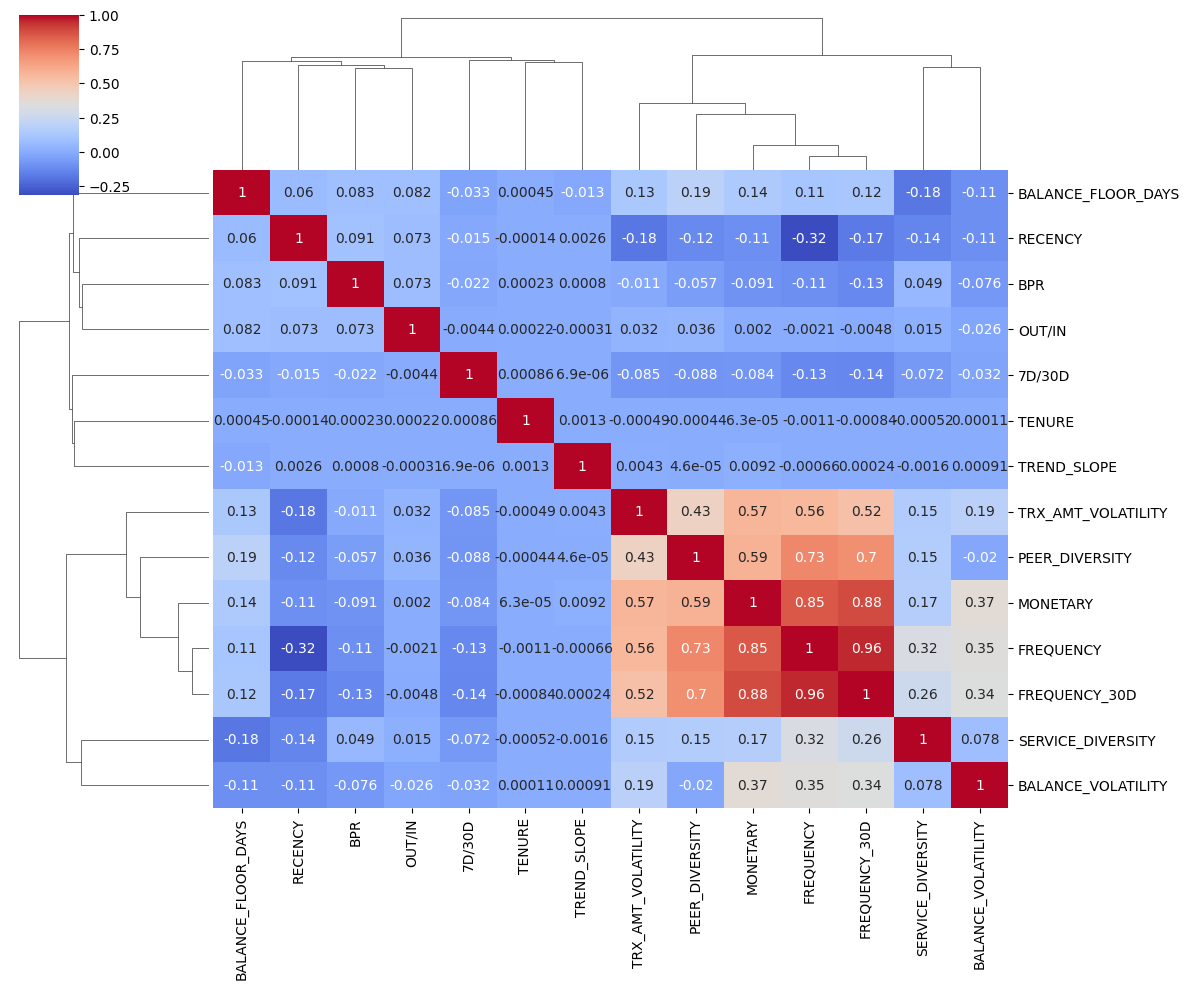

In [23]:
#--Show the relation between different features (may use plots)

corr = final.drop(columns=['ACCOUNT_ID']).corr().compute()
sns.clustermap(corr, annot=True, cmap="coolwarm", figsize=(12,10))
plt.show()

In [24]:
final_train= final.merge(train, on= "ACCOUNT_ID", how="inner")
final_train = final_train.sample(frac=0.1, random_state=42).compute()
X_train = final_train.drop(columns=["ACCOUNT_ID", "CHURN"])
y_train = final_train["CHURN"]

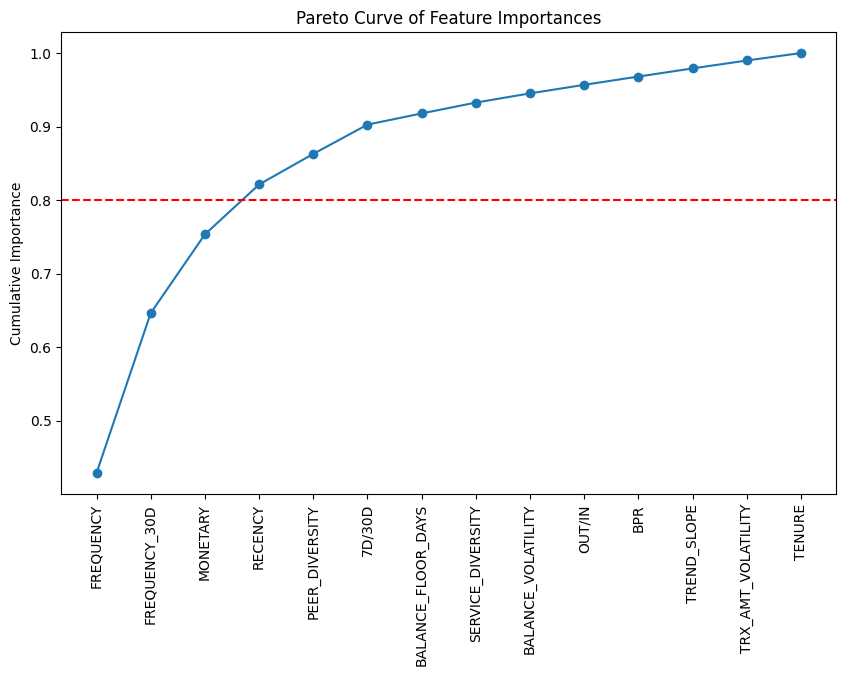

In [25]:
#--find 80% most important features

model = XGBClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
importances = model.feature_importances_
features = X_train.columns

sorted_idx = np.argsort(importances)[::-1]
sorted_features = features[sorted_idx]
sorted_importances = importances[sorted_idx]
cum_importance = np.cumsum(sorted_importances)

plt.figure(figsize=(10,6))
plt.plot(range(len(sorted_importances)), cum_importance, marker='o')
plt.axhline(y=0.8, color='r', linestyle='--')  # 80% cutoff line
plt.xticks(range(len(sorted_features)), sorted_features, rotation=90)
plt.ylabel("Cumulative Importance")
plt.title("Pareto Curve of Feature Importances")
plt.show()

# Features up to the red line = top 80%.

In [26]:
top_features = sorted_features[cum_importance <= 0.8]
print("Top features covering 80% importance:", list(top_features))

Top features covering 80% importance: ['FREQUENCY', 'FREQUENCY_30D', 'MONETARY']


In [27]:
#--Skewness check: |skew| > 1 needs fixing

skew_vals = final.drop(columns=["ACCOUNT_ID"]).skew().compute()
skew_vals

RECENCY                1.939888
FREQUENCY              1.669986
FREQUENCY_30D          1.693513
MONETARY               2.888964
BPR                    1.859828
TENURE                -0.601730
SERVICE_DIVERSITY      0.098614
BALANCE_VOLATILITY    12.535566
TRX_AMT_VOLATILITY     1.560163
TREND_SLOPE            3.599767
OUT/IN                60.875586
PEER_DIVERSITY         2.256907
BALANCE_FLOOR_DAYS    -1.133604
7D/30D                 2.374810
dtype: float64

In [28]:
#--log1p transform: fixes right-skewed data

final['RECENCY_log'] = np.log1p(final['RECENCY'])
final['FREQUENCY_log'] = np.log1p(final['FREQUENCY'])
final['FREQUENCY_30D_log'] = np.log1p(final['FREQUENCY_30D'])
final['MONETARY_log'] = np.log1p(final['MONETARY'])
final['BPR_log'] = np.log1p(final['BPR'])
final['BALANCE_VOLATILITY_log'] = np.log1p(final['BALANCE_VOLATILITY'])
final['TRX_AMT_VOLATILITY_log'] = np.log1p(final['TRX_AMT_VOLATILITY'])
final['TREND_SLOPE_log'] = np.log1p(final['TREND_SLOPE'])
final['OUT/IN_log'] = np.log1p(final['OUT/IN'])
final['PEER_DIVERSITY_log'] = np.log1p(final['PEER_DIVERSITY'])
final['BALANCE_FLOOR_DAYS_log'] = np.log1p(final['BALANCE_FLOOR_DAYS'])
final['7D/30D_log'] = np.log1p(final['7D/30D'])

In [29]:
final= final.drop(columns=['RECENCY', 'FREQUENCY', 'FREQUENCY_30D', 'MONETARY', 'BPR', 'BALANCE_VOLATILITY', 'TRX_AMT_VOLATILITY', 'TREND_SLOPE', 'OUT/IN', 'PEER_DIVERSITY', 'BALANCE_FLOOR_DAYS', '7D/30D'])
final= final.rename(columns={'RECENCY_log':'RECENCY', 'FREQUENCY_log':'FREQUENCY', 'FREQUENCY_30D_log':'FREQUENCY_30D', 'MONETARY_log':'MONETARY','BPR_log':'BPR', 'BALANCE_VOLATILITY_log':'BALANCE_VOLATILITY', 'TRX_AMT_VOLATILITY_log':'TRX_AMT_VOLATILITY', 'TREND_SLOPE_log':'TREND_SLOPE', 'OUT/IN_log':'OUT/IN', 'PEER_DIVERSITY_log':'PEER_DIVERSITY', 'BALANCE_FLOOR_DAYS_log':'BALANCE_FLOOR_DAYS', '7D/30D_log':'7D/30D'})

In [ ]:
#--Zero-inflation flag: >20% zeros → add binary flag. Mention indicator flags with semantic rationale.

col = ['RECENCY', 'FREQUENCY', 'FREQUENCY_30D', 'MONETARY', 'BPR', 'BALANCE_VOLATILITY', 'OUT/IN', 'PEER_DIVERSITY', '7D/30D']
zero_ratio = (final[col] == 0).mean().compute()

for c in col:
    if zero_ratio[c] > 0.2:  
        final[c+'_ZERO_FLAG'] = (final[c]==0).astype(int)

In [31]:
#--Before/after plot: show distribution improved


skewed_features = ["RECENCY", "FREQUENCY", "FREQUENCY_30D", "MONETARY", "BPR", "BALANCE_VOLATILITY", "TRX_AMT_VOLATILITY","TREND_SLOPE", "OUT/IN", "PEER_DIVERSITY", "BALANCE_FLOOR_DAYS", "7D/30D"]

for feat in skewed_features:
   plt.figure(figsize=(6,4))
    sns.histplot(df[feat], color="red", label="Before", kde=True, alpha=0.5)
    sns.histplot(final[feat], color="blue", label="After log1p", kde=True, alpha=0.5)
    plt.title(f"{feat}: Before vs After")
    plt.legend()
    plt.show()

In [ ]:
#--Build a table: Feature | Skew raw | Transform applied | Skew after. 

results = []
skewed_features = ["RECENCY", "FREQUENCY", "FREQUENCY_30D", "MONETARY", "BPR", "BALANCE_VOLATILITY", "TRX_AMT_VOLATILITY","TREND_SLOPE", "OUT/IN", "PEER_DIVERSITY", "BALANCE_FLOOR_DAYS", "7D/30D"]


for feat in skewed_features:
    raw_skew = skew(df[feat].dropna())
    transformed_feat = f"{feat}"
    if transformed_feat in final.columns:
        after_skew = skew(final[transformed_feat].dropna())
        transform_applied = "log1p"
    else:
        after_skew = raw_skew
        transform_applied = "none"
    
    results.append({
        "Feature": feat,
        "Skew raw": round(raw_skew, 3),
        "Transform applied": transform_applied,
        "Skew after": round(after_skew, 3)
    })

skew_table = pd.DataFrame(results)
print(skew_table)

## Class Imbalances

In [10]:
y_train.value_counts(normalize=True)

# As churners are only ~13%, accuracy becomes misleading (a model predicting “no churn” for everyone gets 95% accuracy but is useless)

CHURN
0    0.870605
1    0.129395
Name: proportion, dtype: float64

In [11]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X_train, y_train,
    test_size=0.3,
    random_state=42,
    stratify=y_train
)

In [49]:
#--class_weight: easiest fix, built into LGBM

model = LGBMClassifier(class_weight='balanced', random_state=42)
model.fit(X_train1.values, y_train1.values)

y_pred_proba = model.predict_proba(X_test1.values)[:,1]
weight_auc = roc_auc_score(y_test1, y_pred_proba)
threshold = np.percentile(y_pred_proba, 90)  # top 10%
y_pred_top = (y_pred_proba >= threshold).astype(int)
weight_precision_at_k = precision_score(y_test1, y_pred_top)
weight_recall_at_k = recall_score(y_test1, y_pred_top)

print("CV auc:", weight_auc)
print("Precision@10%:", weight_precision_at_k)
print("Recall@10%:", weight_recall_at_k)

CV auc: 0.9816121780407495
Precision@10%: 0.9092436974789916
Recall@10%: 0.7025974025974026


In [50]:
#--SMOTE: synthetic minority oversampling

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train1, y_train1)

model = LGBMClassifier(random_state=42)
model.fit(X_resampled, y_resampled)

y_pred_proba = model.predict_proba(X_test1)[:,1]
smote_auc = roc_auc_score(y_test1, y_pred_proba)
threshold = np.percentile(y_pred_proba, 90)  # top 10%
y_pred_top = (y_pred_proba >= threshold).astype(int)
smote_precision_at_k = precision_score(y_test1, y_pred_top)
smote_recall_at_k = recall_score(y_test1, y_pred_top)

print("CV auc:", smote_auc)
print("Precision@10%:", smote_precision_at_k)
print("Recall@10%:", smote_recall_at_k)

CV auc: 0.9788497634926205
Precision@10%: 0.9053221288515406
Recall@10%: 0.6995670995670996


In [51]:
#--Undersampling: reduce majority class

rus = RandomUnderSampler(random_state=42)
X_resampled, y_resampled = rus.fit_resample(X_train1, y_train1)

model = LGBMClassifier(random_state=42)
model.fit(X_resampled, y_resampled)

y_pred_proba = model.predict_proba(X_test1)[:,1]
under_auc = roc_auc_score(y_test1, y_pred_proba)
threshold = np.percentile(y_pred_proba, 90)  # top 10%
y_pred_top = (y_pred_proba >= threshold).astype(int)
under_precision_at_k = precision_score(y_test1, y_pred_top)
under_recall_at_k = recall_score(y_test1, y_pred_top)

print("CV auc:", under_auc)
print("Precision@10%:", under_precision_at_k)
print("Recall@10%:", under_recall_at_k)

CV auc: 0.9804504643790357
Precision@10%: 0.8952380952380953
Recall@10%: 0.6917748917748918


In [52]:
#--Build a table named 'Strategy comparison' like workshop slide

results = [
    {
        "Strategy": "class_weight='balanced'",
        "CV AUC": weight_auc,
        "Prec@10%": weight_precision_at_k,
        "Rec@10%": weight_recall_at_k
    },
    {
        "Strategy": "Undersampling",
        "CV AUC": under_auc,
        "Prec@10%": under_precision_at_k,
        "Rec@10%": under_recall_at_k
    },
    {
        "Strategy": "SMOTE",
        "CV AUC": smote_auc,
        "Prec@10%": smote_precision_at_k,
        "Rec@10%": smote_recall_at_k
    }
]

strategy_table = pd.DataFrame(results)
print(strategy_table)

                  Strategy    CV AUC  Prec@10%   Rec@10%
0  class_weight='balanced'  0.981612  0.909244  0.702597
1            Undersampling  0.980450  0.895238  0.691775
2                    SMOTE  0.978850  0.905322  0.699567


In [ ]:
#'Missing a churner costs more than a false alarm, so we prefer higher recall → class_weight=balanced wins.'

## Model Training

In [ ]:
#(Churn detection:'Churn' means inactive for 30 days as mentioned in the workshop)

#--train a Logistic Regression as baseline — it shows comparison. LightGBM tuned will be the submission model.
#--LightGBM: our main model — fast & accurate
#--AUC-ROC: 40% of auto-score
#--Avg Precision: 25% — handles imbalance
#--Precision@K: 20% — top decile accuracy
#--Recall@K: 15% — churn coverage

#--Build a table on model comparision as in workshop slide: Model | AUC | AvgPrec | P@10% | Lift

In [48]:
# Logistic Regression baseline

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train1, y_train1)

y_pred_proba_lr = logreg.predict_proba(X_test1)[:,1]

auc_lr = roc_auc_score(y_test1, y_pred_proba_lr)
ap_lr = average_precision_score(y_test1, y_pred_proba_lr)

#Precision@10%  means (top decile)
threshold_lr = np.percentile(y_pred_proba_lr, 90)
p_at10_lr = precision_score(y_test1, (y_pred_proba_lr >= threshold_lr).astype(int))

# Lift means Precision@10% / baseline churn rate
baseline_rate = y_test1.mean()
lift_lr = p_at10_lr / baseline_rate

In [ ]:
predictions_lr = final_test.compute()
y_pred_proba = logreg.predict_proba(X_test)[:, 1]
predictions_lr["Y_TEST"] = y_pred_proba
predictions_lr["CHURN"] = (y_pred_proba >= threshold_lr).astype(int)
predictions_lr = predictions_lr[["ACCOUNT_ID", "CHURN"]]
predictions_lr.to_csv("/kaggle/working/predictions_lr.csv", index=False)

In [17]:
# LightGBM default

lgbm_default = LGBMClassifier(random_state=42)
lgbm_default.fit(X_train1, y_train1)

y_pred_proba_lgb = lgbm_default.predict_proba(X_test1)[:,1]

auc_lgb = roc_auc_score(y_test1, y_pred_proba_lgb)
ap_lgb = average_precision_score(y_test1, y_pred_proba_lgb)

threshold_lgb = np.percentile(y_pred_proba_lgb, 90)
p_at10_lgb = precision_score(y_test1, (y_pred_proba_lgb >= threshold_lgb).astype(int))

baseline_rate = y_test1.mean()
lift_lgb = p_at10_lgb / baseline_rate

[LightGBM] [Info] Number of positive: 5389, number of negative: 36261
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000958 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2998
[LightGBM] [Info] Number of data points in the train set: 41650, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.129388 -> initscore=-1.906383
[LightGBM] [Info] Start training from score -1.906383


In [ ]:
predictions_lgb = final_test.compute()
y_pred_proba = lgbm_default.predict_proba(X_test)[:, 1]
predictions_lgb["Y_TEST"] = y_pred_proba
predictions_lgb["CHURN"] = (y_pred_proba >= threshold_lgb).astype(int)
predictions_lgb = predictions_lgb[["ACCOUNT_ID", "CHURN"]]
predictions_lgb.to_csv("/kaggle/working/predictions_lgb.csv", index=False)

In [18]:
# LightGBM tuned

lgbm_tuned = LGBMClassifier(
    learning_rate=0.05,
    num_leaves=64,
    max_depth=-1,
    n_estimators=500,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
lgbm_tuned.fit(X_train1, y_train1)

y_pred_proba_tuned = lgbm_tuned.predict_proba(X_test1)[:,1]

auc_tuned = roc_auc_score(y_test1, y_pred_proba_tuned)
ap_tuned = average_precision_score(y_test1, y_pred_proba_tuned)

threshold_tuned = np.percentile(y_pred_proba_tuned, 90)
p_at10_tuned = precision_score(y_test1, (y_pred_proba_tuned >= threshold_tuned).astype(int))

baseline_rate = y_test1.mean()
lift_tuned = p_at10_tuned / baseline_rate

[LightGBM] [Info] Number of positive: 5389, number of negative: 36261
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003973 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2998
[LightGBM] [Info] Number of data points in the train set: 41650, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.129388 -> initscore=-1.906383
[LightGBM] [Info] Start training from score -1.906383


In [ ]:
predictions_tuned = final_test.compute()
y_pred_proba = lgbm_tuned.predict_proba(X_test)[:, 1]
predictions_tuned["Y_TEST"] = y_pred_proba
predictions_tuned["CHURN"] = (y_pred_proba >= threshold_tuned).astype(int)
predictions_tuned = predictions_tuned[["ACCOUNT_ID", "CHURN"]]
predictions_tuned.to_csv("/kaggle/working/predictions_tuned.csv", index=False)

In [19]:
#--Build a table on model comparision as in workshop slide: Model | AUC | AvgPrec | P@10% | Lift

results = pd.DataFrame({
    "Model": ["Logistic Regression", "LightGBM (default)", "LightGBM (tuned)"],
    "AUC": [auc_lr, auc_lgb, auc_tuned],
   "AvgPrec": [ap_lr, ap_lgb, ap_tuned],
    "P@10%": [p_at10_lr, p_at10_lgb, p_at10_tuned],
    "Lift": [lift_lr, lift_lgb, lift_tuned]
})

print(results.round(3))

                 Model    AUC  AvgPrec  P@10%   Lift
0  Logistic Regression  0.943    0.794  0.798  6.169
1   LightGBM (default)  0.981    0.906  0.906  7.000
2     LightGBM (tuned)  0.981    0.903  0.906  7.000


## Hyper-parameter Tuning

In [29]:
#--Optuna: Bayesian optimization
#--suggest_int/float: define search space

def objective(trial):
    param = {
        "objective": "binary",
        "metric": "auc",
        "boosting_type": "gbdt",
        "num_leaves": trial.suggest_int("num_leaves", 20, 200),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "random_state": 42,
        "verbosity": -1
    }

    model = lgb.LGBMClassifier(**param)
    model.fit(X_train1, y_train1, eval_set=[(X_test1, y_test1)], eval_metric="auc")

    y_pred = model.predict_proba(X_test1)[:, 1]
    auc = roc_auc_score(y_test1, y_pred)
    return auc


In [30]:
#--n_trials=100: 

optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=100, show_progress_bar=True)

  0%|          | 0/100 [00:00<?, ?it/s]

In [47]:
#--Convergence plot: score vs iteration chart, report best parameters

import optuna.visualization as vis

fig = vis.plot_optimization_history(study)
fig.show()

In [32]:
#--Before vs after show AUC improvement:

default_model = lgb.LGBMClassifier(random_state=42)
default_model.fit(X_train1, y_train1)
y_pred_default = default_model.predict_proba(X_test1)[:, 1]
auc_default = roc_auc_score(y_test1, y_pred_default)

# Tuned LightGBM
tuned_model = lgb.LGBMClassifier(**study.best_params)
tuned_model.fit(X_train1, y_train1)
y_pred_tuned = tuned_model.predict_proba(X_test1)[:, 1]
auc_tuned = roc_auc_score(y_test1, y_pred_tuned)

print("Default AUC:", auc_default)
print("Tuned AUC:", auc_tuned)

Default AUC: 0.9813469081326224
Tuned AUC: 0.9830577841292126


In [33]:
#--Decision: is hyperparameter tuning really needed? if yes, then which of the parameters to be tuned?? Explain.

print("Best Parameters:", study.best_params)
print("Best AUC:", study.best_value)

Best Parameters: {'num_leaves': 41, 'max_depth': 10, 'learning_rate': 0.011486999742326066, 'n_estimators': 466, 'subsample': 0.5559879940971774, 'colsample_bytree': 0.7344249092457469}
Best AUC: 0.9829549633121061


## Explainability

In [ ]:
# 15) Explainability:

#--SHAP values: feature contribution per prediction. Show Shap values per Feature along with Direction (as a table in workshop slide)

#--TreeExplainer: fast SHAP for tree models

#--Beeswarm plot: summary of all features

#--Dependence plot: one feature's effect

#--Leakage audit: check for future data use

#--Explain top drivers in plain business language; flag counter-intuitive ones

#--Explain the top 3 SHAP features like: 'freq_30d has the highest impact — users with fewer monthly transactions are more likely to churn.'

 99%|===================| 17757/17850 [01:01<00:00]        

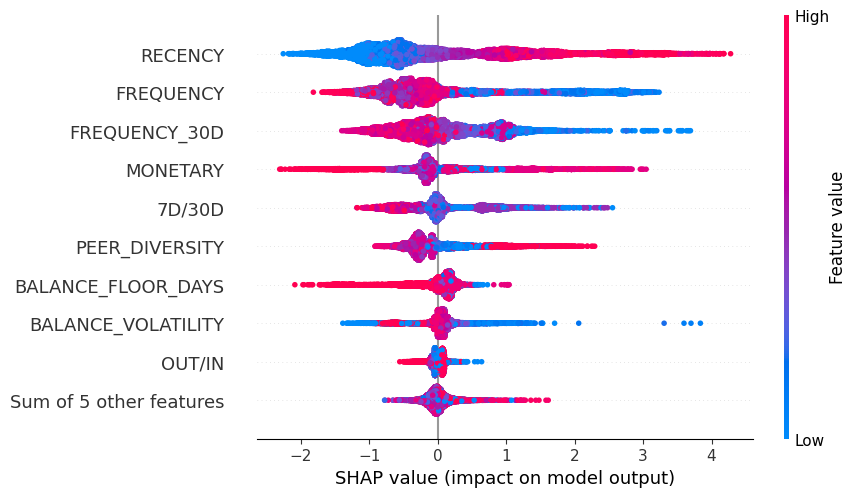

In [34]:
#shap for lgbm default

explainer = shap.Explainer(lgbm_default, X_test1)
shap_values_lgbm_def = explainer(X_test1)

# Summary plot
shap.plots.beeswarm(shap_values_lgbm_def)

In [35]:
#feature and mean |shap| for lgbm default

shap_importance_lgbmd = pd.DataFrame({
    "feature": X_test1.columns,
    "mean_abs_shap": np.abs(shap_values_lgbm_def.values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print(shap_importance_lgbmd)

               feature  mean_abs_shap
2              RECENCY       0.968074
3            FREQUENCY       0.702293
4        FREQUENCY_30D       0.507804
5             MONETARY       0.418450
13              7D/30D       0.380720
11      PEER_DIVERSITY       0.332224
12  BALANCE_FLOOR_DAYS       0.222966
7   BALANCE_VOLATILITY       0.169750
10              OUT/IN       0.064918
8   TRX_AMT_VOLATILITY       0.056220
0               TENURE       0.041128
9          TREND_SLOPE       0.038932
6                  BPR       0.038307
1    SERVICE_DIVERSITY       0.034254


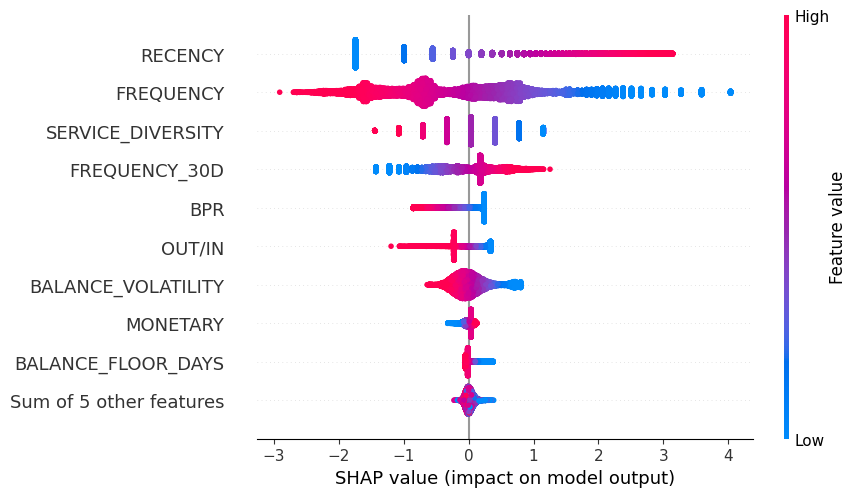

In [37]:
#shap values for logistic regression

explainer = shap.Explainer(logreg, X_test1)
shap_values_logreg = explainer(X_test1)

# Summary plot
shap.plots.beeswarm(shap_values_logreg)

In [39]:
#feature and mean |shap| for logistic regression

shap_importance_logreg = pd.DataFrame({
    "feature": X_test1.columns,
    "mean_abs_shap": np.abs(shap_values_logreg.values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print(shap_importance_logreg)

               feature  mean_abs_shap
2              RECENCY       1.335075
3            FREQUENCY       1.097139
1    SERVICE_DIVERSITY       0.462501
4        FREQUENCY_30D       0.431732
6                  BPR       0.262658
10              OUT/IN       0.246627
7   BALANCE_VOLATILITY       0.190802
5             MONETARY       0.054378
12  BALANCE_FLOOR_DAYS       0.045476
11      PEER_DIVERSITY       0.036869
13              7D/30D       0.026211
8   TRX_AMT_VOLATILITY       0.024644
0               TENURE       0.018170
9          TREND_SLOPE       0.004201


100%|===================| 17823/17850 [07:48<00:00]        

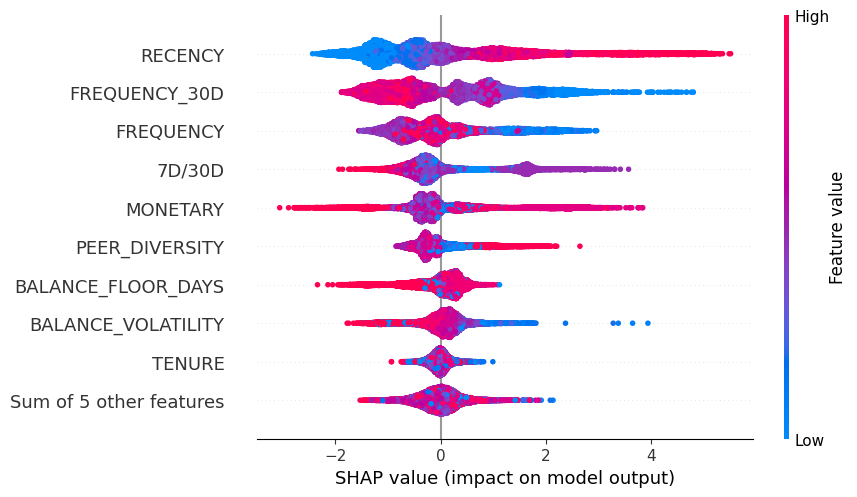

In [41]:
#shap values for lgbm tuned

explainer = shap.Explainer(lgbm_tuned, X_test1)
shap_values_lgbm_tuned = explainer(X_test1)

# Summary plot
shap.plots.beeswarm(shap_values_lgbm_tuned)

In [42]:
#feature and mean |shap| for lgbm tuned

shap_importance_lgbmt = pd.DataFrame({
    "feature": X_test1.columns,
    "mean_abs_shap": np.abs(shap_values_lgbm_tuned.values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print(shap_importance_lgbmt)

               feature  mean_abs_shap
2              RECENCY       1.102064
4        FREQUENCY_30D       0.958248
3            FREQUENCY       0.637003
13              7D/30D       0.611013
5             MONETARY       0.591430
11      PEER_DIVERSITY       0.351910
12  BALANCE_FLOOR_DAYS       0.320143
7   BALANCE_VOLATILITY       0.299387
0               TENURE       0.129149
8   TRX_AMT_VOLATILITY       0.113341
6                  BPR       0.110686
10              OUT/IN       0.095417
9          TREND_SLOPE       0.089217
1    SERVICE_DIVERSITY       0.084267


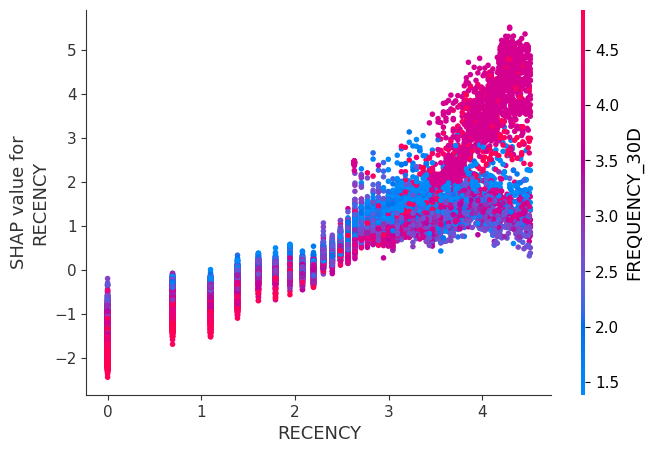

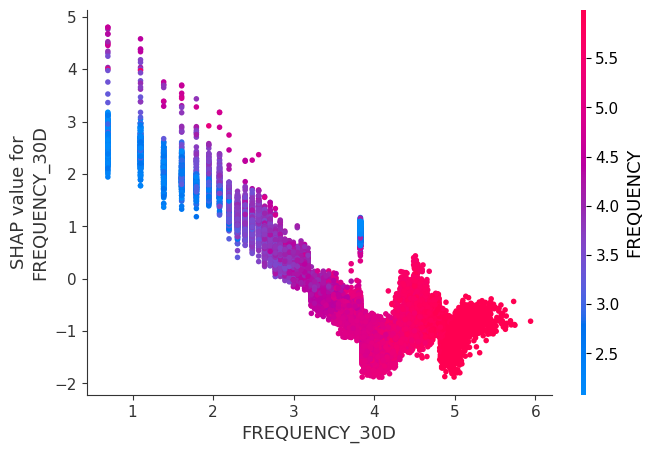

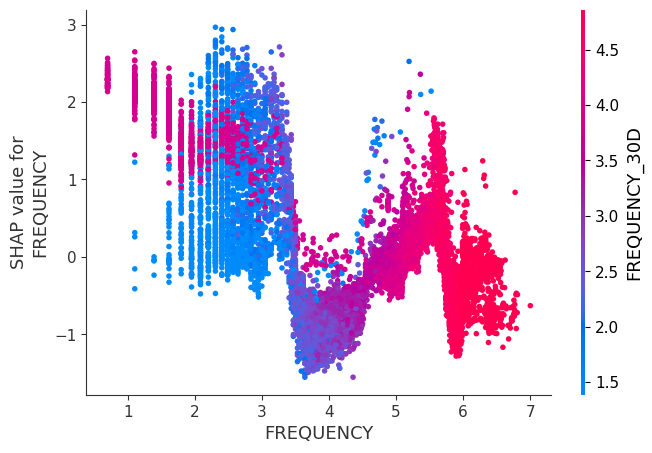

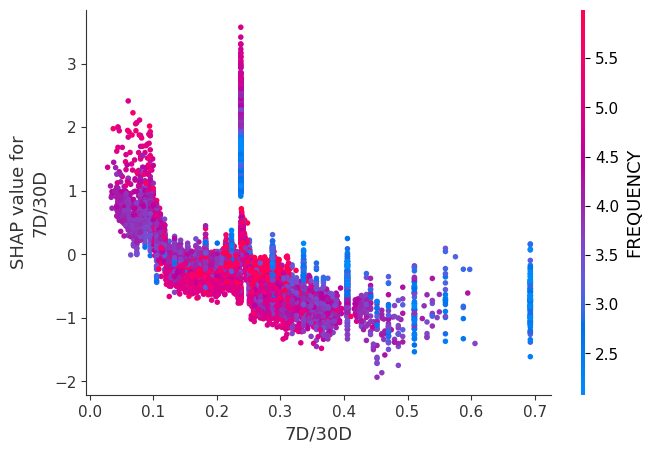

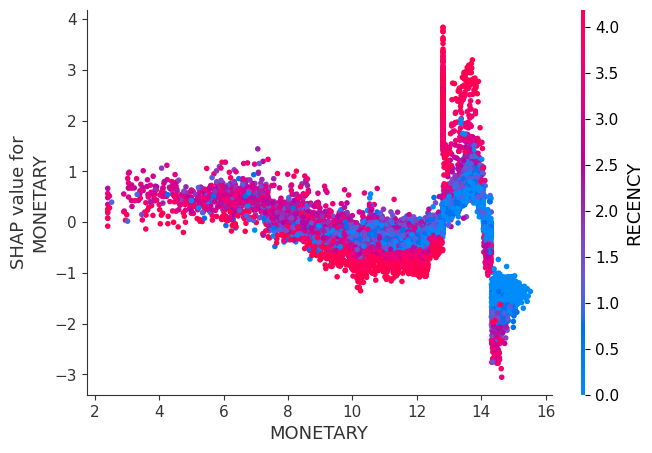

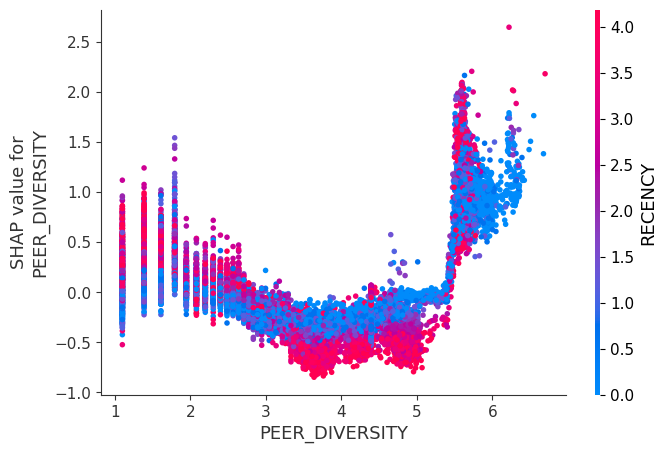

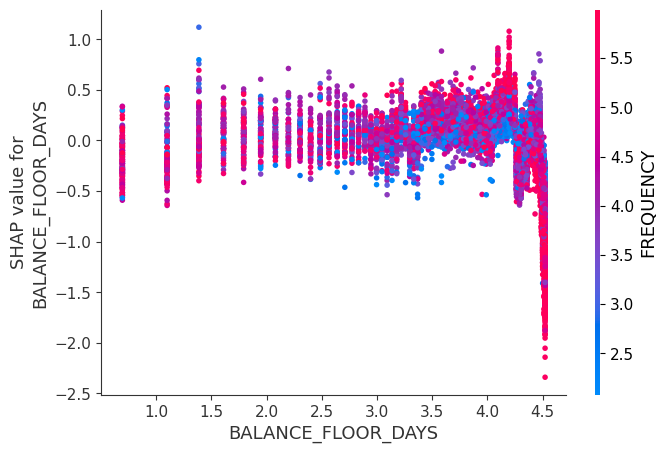

In [43]:
col = shap_importance_lgbmt["feature"]
col.tolist()
i=0
for c in col:
    shap.dependence_plot(c, shap_values_lgbm_tuned.values, X_test1)
    if i>5:
        break
    i = i+1

In [45]:
# data leakage

max_date = df2["TRX_DATETIME"].max().compute()
max_date_df2 = max_date
max_date_df1 = df1["ACCOUNT_OPEN_DATE"].max().compute()
df3["DATE"] = dd.to_datetime(df3["DATE"])
max_date_df3 = df3["DATE"].max().compute()

In [46]:
print(max_date_df1, max_date_df2, max_date_df3)

#no data available in the train set after today(prediction date)
#so no data leakage

2023-10-27 00:00:00 2024-03-31 22:59:57 2024-03-31 00:00:00


## Business Recommendation

In [ ]:
# 16) Business recs

#--Decision rule with a lift estimate: flag top X% → take action

#--Lift table: precision/recall at each threshold (workshop slide)

#--Interventions: tied to SHAP insights

#--5-slide deck: executive-ready presentation

#Link every intervention to a SHAP insight: 'freq_30d is top driver → send re-engagement push notification to low-frequency users 2 weeks before predicted churn.'